# Unsupervised — Clustering Data Campuran (kolom angka + kategori)
**Kapan dipakai:** data untuk dikelompokkan berisi kolom angka DAN kategori (kota, jenis
kelamin, tipe produk). KMeans biasa hanya paham angka.

**Idenya:** dua cara:
- **K-Prototypes** (paket `kmodes`): jarak biasa untuk angka + jumlah kategori yang beda.
- **Jarak Gower** + Agglomerative: tiap kolom diberi jarak 0–1, lalu dirata-rata.

**Langkah:**
1. Siapkan kolom angka (skala disamakan) dan kolom kategori.
2. Hitung matriks jarak Gower (untuk model Agglomerative dan nilai silhouette).
3. Latih model, lihat profil cluster, simpan label cluster.

**Data demo:** Penguins (angka: paruh, sirip, berat, kategori: pulau, jenis kelamin).
`species` hanya untuk cek.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from kmodes.kprototypes import KPrototypes
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/unsupervised"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/penguins.csv"

LABEL_COL = "species"    # hanya untuk cek
NUMBER_COLS = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
CATEGORY_COLS = ["island", "sex"]
N_CLUSTERS = 3
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
print(data.shape)
missing_per_column = data.isna().sum()
print("missing total:", missing_per_column.sum())
print(data[NUMBER_COLS].describe().round(1))
data.head()

(333, 7)
missing total: 0
       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count           333.0          333.0              333.0        333.0
mean             44.0           17.2              201.0       4207.1
std               5.5            2.0               14.0        805.2
min              32.1           13.1              172.0       2700.0
25%              39.5           15.6              190.0       3550.0
50%              44.5           17.3              197.0       4050.0
75%              48.6           18.7              213.0       4775.0
max              59.6           21.5              231.0       6300.0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


## Langkah 1 — kolom angka + kategori
K-Prototypes perlu tahu nomor kolom yang kategori (`CATEGORY_POSITIONS`).

In [4]:
scaler = StandardScaler()
numbers = scaler.fit_transform(data[NUMBER_COLS])
X_mixed = np.column_stack([numbers, data[CATEGORY_COLS].to_numpy()])
X_mixed = X_mixed.astype(object)
CATEGORY_POSITIONS = []
for i in range(len(CATEGORY_COLS)):
    CATEGORY_POSITIONS.append(len(NUMBER_COLS) + i)
print(X_mixed[:3])

[[-0.8960418897725922 0.7807321043966328 -1.4267515672137063
  -0.5684747832140795 'Torgersen' 'Male']
 [-0.822787866745704 0.11958396669455443 -1.0694735766270285
  -0.5062861817652331 'Torgersen' 'Female']
 [-0.6762798206919277 0.4247292610185911 -0.4263731935710082
  -1.1903607977025437 'Torgersen' 'Female']]


## Langkah 2 — jarak Gower
Kolom angka: selisih dibagi rentang kolom (hasil 0–1). Kolom kategori: 0 kalau sama, 1 kalau
beda. Jarak dua baris = rata-rata semua kolom.

In [5]:
def gower_distance(table):
    values = table[NUMBER_COLS].to_numpy(dtype=float)
    value_range = values.max(axis=0) - values.min(axis=0)
    total = np.zeros((len(table), len(table)))
    for i in range(len(NUMBER_COLS)):
        column = values[:, i]
        total += np.abs(column[:, None] - column[None, :]) / value_range[i]
    for name in CATEGORY_COLS:
        column = table[name].to_numpy()
        total += column[:, None] != column[None, :]
    return total / (len(NUMBER_COLS) + len(CATEGORY_COLS))


# coba pada 5 baris pertama
print(gower_distance(data.head()).round(2))

gower = gower_distance(data)
print("matriks Gower:", gower.shape)

[[0.   0.33 0.58 0.54 0.25]
 [0.33 0.   0.34 0.42 0.44]
 [0.58 0.34 0.   0.32 0.53]
 [0.54 0.42 0.32 0.   0.45]
 [0.25 0.44 0.53 0.45 0.  ]]
matriks Gower: (333, 333)


## Langkah 3 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

silhouette (jarak Gower): 0.339
1    124
2    119
0     90
Name: count, dtype: int64


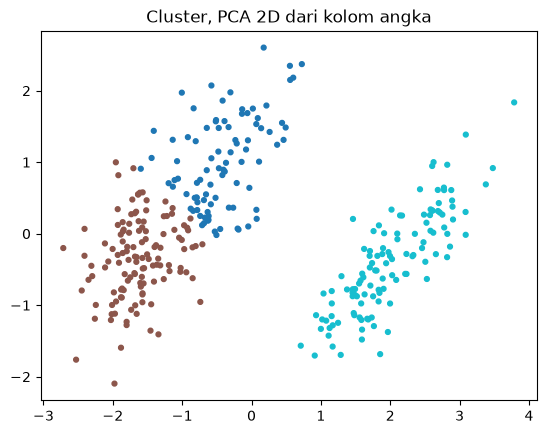

In [6]:
model = KPrototypes(n_clusters=N_CLUSTERS, init="Cao", random_state=SEED)
labels = model.fit_predict(X_mixed, categorical=CATEGORY_POSITIONS)

# model = AgglomerativeClustering(n_clusters=N_CLUSTERS, metric="precomputed",
#                                 linkage="average")
# labels = model.fit_predict(gower)                   # pakai matriks Gower

print("silhouette (jarak Gower):", round(silhouette_score(gower, labels, metric="precomputed"), 3))
print(pd.Series(labels).value_counts())

pca = PCA(n_components=2)
X_2d = pca.fit_transform(numbers)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap="tab10", s=12)
plt.title("Cluster, PCA 2D dari kolom angka")
plt.show()

## Profil tiap cluster
Angka: rata-rata per cluster. Kategori: jumlah tiap nilai per cluster.

In [7]:
profile = data[NUMBER_COLS].groupby(labels).mean()
print(profile.round(1))
for name in CATEGORY_COLS:
    print(pd.crosstab(labels, data[name], rownames=["cluster"]))

   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            47.1           18.9              197.3       3944.7
1            38.3           18.0              188.0       3547.8
2            47.6           15.0              217.2       5092.4
island   Biscoe  Dream  Torgersen
cluster                          
0             7     70         13
1            37     53         34
2           119      0          0
sex      Female  Male
cluster              
0            26    64
1            81    43
2            58    61


## Simpan label cluster

In [8]:
submission = pd.DataFrame()
submission["row"] = data.index
submission["cluster"] = labels
submission.to_csv("submission.csv", index=False)
submission.head()

,row,cluster
0,0,1
1,1,1
2,2,1
3,3,1
4,4,1


## Cek dengan kunci jawaban (HAPUS saat lomba)
ARI = kemiripan cluster dengan label asli (1 = sama persis, 0 = acak).

In [9]:
print("ARI:", round(adjusted_rand_score(data[LABEL_COL], labels), 3))
pd.crosstab(labels, data[LABEL_COL], rownames=["cluster"])

ARI: 0.734


species,Adelie,Chinstrap,Gentoo
cluster,,,
0,30,60,0
1,116,8,0
2,0,0,119
